# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [5]:
import pandas as pd, numpy as np

tx = pd.read_csv('walmart_transactions_cleaned.csv')
tx['timestamp'] = pd.to_datetime(tx['timestamp'])
tx['date'] = tx['timestamp'].dt.normalize()

LANDFALL       = pd.Timestamp('2024-09-26')
BASELINE_START = pd.Timestamp('2024-09-01')
BASELINE_END   = pd.Timestamp('2024-09-18')
SURGE_START    = pd.Timestamp('2024-09-19')
SURGE_END      = pd.Timestamp('2024-09-25')

all_days = pd.date_range('2024-09-01', '2024-09-30')
daily_units = tx.groupby('date')['quantity'].sum().reindex(all_days, fill_value=0)

baseline_days = daily_units[BASELINE_START:BASELINE_END]
surge_days    = daily_units[SURGE_START:SURGE_END]
baseline_avg, surge_avg = baseline_days.mean(), surge_days.mean()
multiple = surge_avg / baseline_avg

print(f'Baseline window: {BASELINE_START:%b %d} to {BASELINE_END:%b %d} ({len(baseline_days)} days)')
print(f'Surge window:    {SURGE_START:%b %d} to {SURGE_END:%b %d} ({len(surge_days)} days)')
print(f'Baseline average: {baseline_avg:,.0f} units/day')
print(f'Surge average:    {surge_avg:,.0f} units/day')
print(f'Surge multiple:   {multiple:.2f}x')

sku_daily = tx.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0).reindex(all_days, fill_value=0)
sku_summary = pd.DataFrame({
    'baseline_avg': sku_daily[BASELINE_START:BASELINE_END].mean(),
    'surge_avg':    sku_daily[SURGE_START:SURGE_END].mean(),
})
sku_summary['multiple'] = sku_summary['surge_avg'] / sku_summary['baseline_avg']
print(sku_summary.sort_values('multiple', ascending=False).head(5).round(2))

Baseline window: Sep 01 to Sep 18 (18 days)
Surge window:    Sep 19 to Sep 25 (7 days)
Baseline average: 1,181 units/day
Surge average:    2,724 units/day
Surge multiple:   2.31x
               baseline_avg  surge_avg  multiple
canonical_sku                                   
POPTART-STRAW         88.22     378.00      4.28
WTR-24               112.39     320.86      2.85
TARP-HD               47.83     130.00      2.72
LED-FLASH             63.00     169.29      2.69
BG-MONO               45.11     113.00      2.50


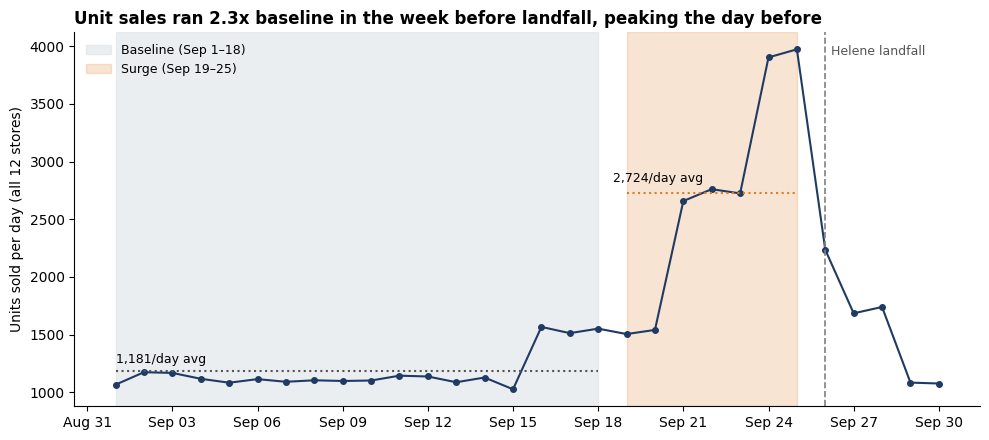

In [6]:
import matplotlib.pyplot as plt, matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_units.index, daily_units.values, marker='o', ms=4, color='#1f3b63')
ax.axvspan(BASELINE_START, BASELINE_END, color='#d9dee4', alpha=0.5, label='Baseline (Sep 1–18)')
ax.axvspan(SURGE_START, SURGE_END, color='#e07b24', alpha=0.2, label='Surge (Sep 19–25)')
ax.hlines(baseline_avg, BASELINE_START, BASELINE_END, color='#555', ls=':', lw=1.5)
ax.hlines(surge_avg, SURGE_START, SURGE_END, color='#e07b24', ls=':', lw=1.5)
ax.annotate(f'{baseline_avg:,.0f}/day avg', (BASELINE_START, baseline_avg), xytext=(0, 6), textcoords='offset points', fontsize=9)
ax.annotate(f'{surge_avg:,.0f}/day avg', (SURGE_START, surge_avg), xytext=(-10, 8), textcoords='offset points', fontsize=9)
ax.axvline(LANDFALL, color='gray', ls='--', lw=1.2)
ax.annotate('Helene landfall', (LANDFALL, daily_units.max()), xytext=(4, -4), textcoords='offset points', fontsize=9, color='#555')
ax.set_title(f'Unit sales ran {multiple:.1f}x baseline in the week before landfall, peaking the day before',
             loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('Units sold per day (all 12 stores)')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, fontsize=9, loc='upper left')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** In the 7 days before Helene’s landfall (Sept 19–25), our 12 Florida stores sold an average of 2,724 units a day, 2.31x the 1,181 a day they sold Sept 1–18, with Pop-Tarts the biggest mover at 4.3x.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct SKUs as recorded: 45
Canonical products after consolidation: 20
SKUs merged away: 25

Largest family: POPTART-STRAW | raw codes: ['PT-12', 'POPTART-STRAW', 'PT_STRAWBERRY', 'SKU#459812']
sku
PT-12            1336
POPTART-STRAW    1245
PT_STRAWBERRY    1238
SKU#459812       1206
Name: quantity, dtype: int64
Consolidated total: 5025
Largest fragment alone: 1,336 units -> consolidated is 3.8x bigger
Unit-volume rank as best raw code: 8 -> consolidated: 2

Assertions passed: total units = 48,134 before and after.


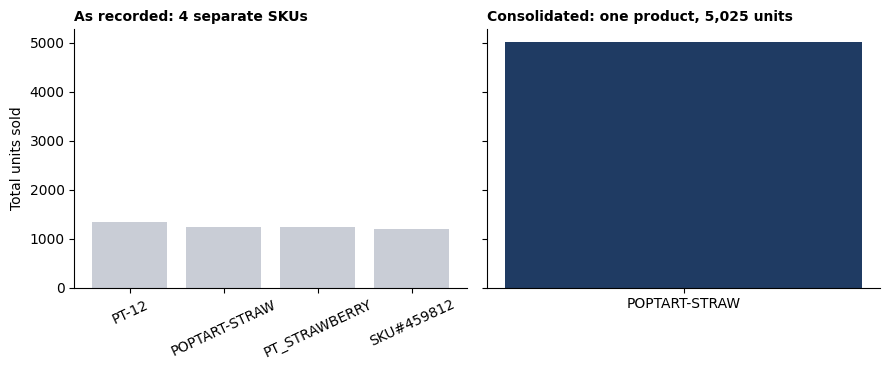

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

tx = pd.read_csv('walmart_transactions_cleaned.csv')
raw = pd.read_csv('walmart_transactions (1).csv')[['transaction_id', 'sku']].drop_duplicates('transaction_id')
tx = tx.merge(raw, on='transaction_id', how='left', validate='one_to_one')
assert tx['sku'].notna().all(), 'Some transactions lost their original SKU.'

raw_count = tx['sku'].nunique()
canonical_count = tx['canonical_sku'].nunique()
print('Distinct SKUs as recorded:', raw_count)
print('Canonical products after consolidation:', canonical_count)
print('SKUs merged away:', raw_count - canonical_count)

family_sizes = tx.groupby('canonical_sku')['sku'].nunique().sort_values(ascending=False)
largest_family = family_sizes.index[0]
fragmented = (tx[tx['canonical_sku'] == largest_family]
              .groupby('sku')['quantity'].sum().sort_values(ascending=False))
consolidated_total = fragmented.sum()
print('\nLargest family:', largest_family, '| raw codes:', list(fragmented.index))
print(fragmented)
print('Consolidated total:', consolidated_total)
print(f'Largest fragment alone: {fragmented.iloc[0]:,} units -> consolidated is {consolidated_total / fragmented.iloc[0]:.1f}x bigger')

raw_rank = tx.groupby('sku')['quantity'].sum().rank(ascending=False, method='min')
canon_rank = tx.groupby('canonical_sku')['quantity'].sum().rank(ascending=False, method='min')
print('Unit-volume rank as best raw code:', int(raw_rank[fragmented.index[0]]),
      '-> consolidated:', int(canon_rank[largest_family]))

assert tx.groupby('sku')['quantity'].sum().sum() == tx.groupby('canonical_sku')['quantity'].sum().sum(), 'Consolidation changed total units.'
assert consolidated_total == tx.loc[tx['canonical_sku'] == largest_family, 'quantity'].sum()
assert tx.groupby('sku')['canonical_sku'].nunique().max() == 1, 'A raw SKU maps to more than one canonical SKU.'
print(f"\nAssertions passed: total units = {tx['quantity'].sum():,} before and after.")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} separate SKUs', fontsize=10, loc='left', fontweight='bold')
axes[0].tick_params(axis='x', labelrotation=25)
axes[0].set_ylabel('Total units sold')
axes[1].bar([largest_family], [consolidated_total], color='#1f3b63')
axes[1].set_title(f'Consolidated: one product, {consolidated_total:,} units', fontsize=10, loc='left', fontweight='bold')
for ax in axes:
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Q2 answer:** We consolidated 45 distinct SKUs into 20 canonical products without changing the 48,134-unit total (asserted in code). The largest family, Pop-Tarts, was spread across 4 codes, and its best single code (PT-12, 1,336 units) ranked only 8th. Combined, it is 5,025 units, 3.8x its biggest fragment and the #2 product overall.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Weather retrieval succeeded.
Weather source used: open-meteo
_merge
both          24648
left_only         0
right_only        0
Name: count, dtype: int64
Number of sales days with no weather: 0
Rows kept by the left join: 24648 of 24648
All checks passed.


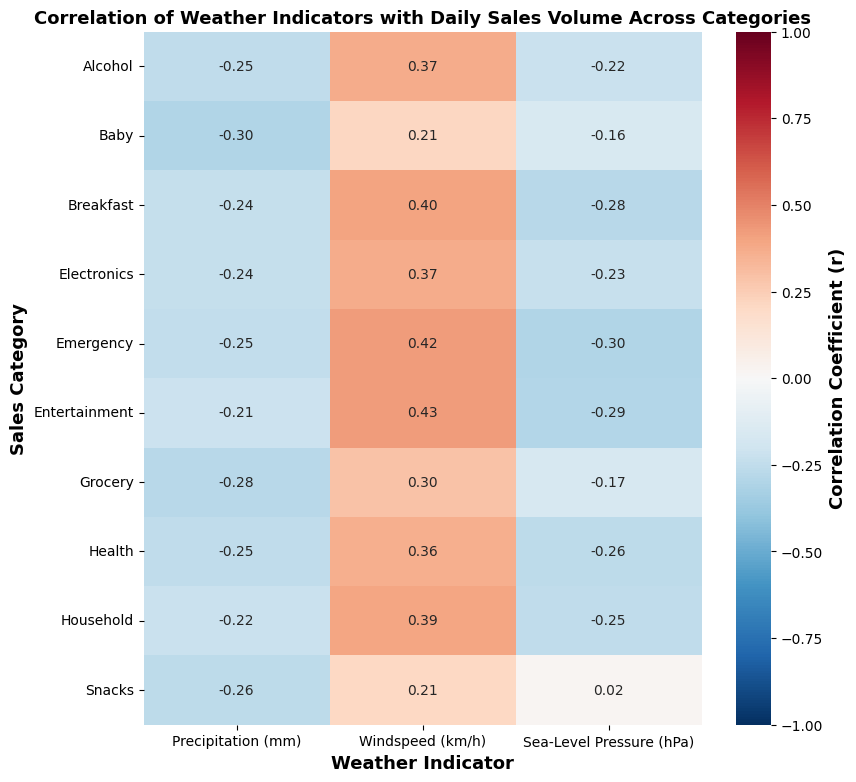

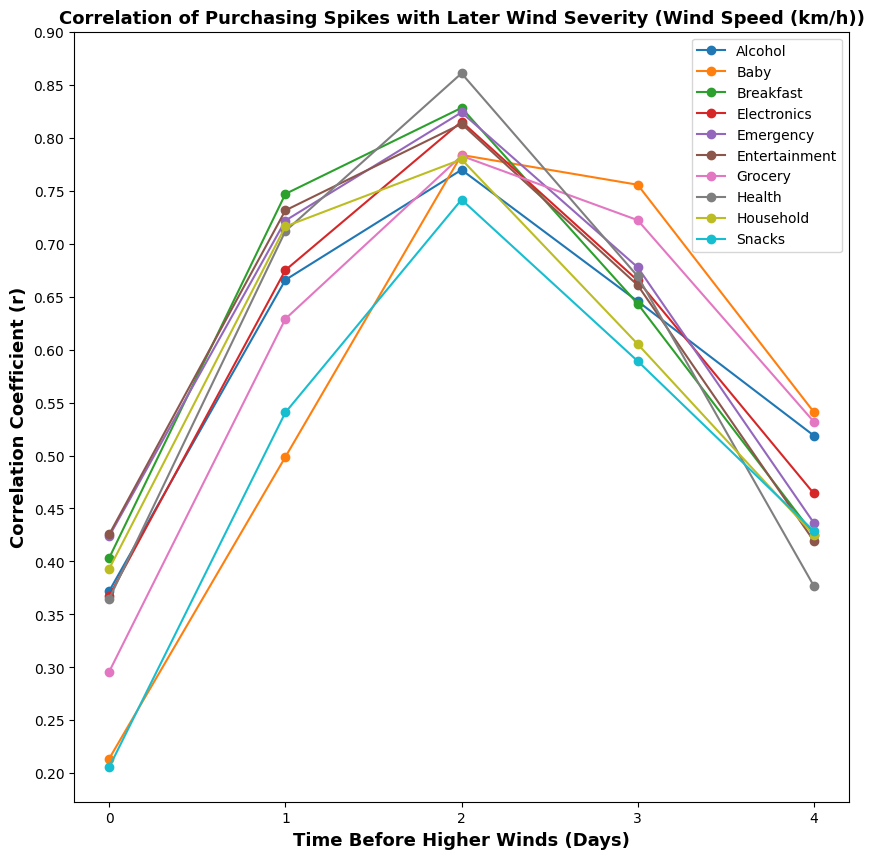

In [4]:
import pandas as pd
import requests
import time
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def weather_retrieval(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'pressure_msl_mean': [1014.1, 1014.1, 1015.7, 1017.8, 1017.3, 1014.3, 1011.9, 1013.8,
                          1015.7, 1014.3, 1012.3, 1011.8, 1012.7, 1012.2, 1011.8, 1012.9, 1013.7,
                          1012.9, 1011.2, 1010.6, 1012.5, 1012.7, 1013.2, 1013.5, 1011.7, 1004.1, 1006.7, 1012.3, 1013.1, 1013.8],
    'source': 'fallback sample',
})

def weather_sales_join(sales_data, weather_data):
    sales_data = sales_data.copy()
    sales_data['date'] = sales_data['timestamp'].dt.normalize()

    merged = sales_data.merge(weather_data, on='date', how='left', indicator=True, validate='many_to_one')
    unmatched = merged.loc[merged['_merge'] == 'left_only', 'date'].drop_duplicates()

    print(merged['_merge'].value_counts())
    print('Number of sales days with no weather:', len(unmatched))
    if(len(unmatched) > 0):
        print('Sales days with no weather:', unmatched.dt.date.tolist())
    print('Rows kept by the left join:', len(merged), 'of', len(sales_data))

    assert len(merged) == len(sales_data), 'The join changed the row count.'
    assert merged['quantity'].sum() == sales_data['quantity'].sum(), 'The quantity total changed.'
    assert len(unmatched) == 0, 'There are sales days with no weather.'
    print('All checks passed.')

    return merged

try:
    weather = weather_retrieval('2024-09-01', '2024-09-30')
    print('Weather retrieval succeeded.')
except requests.RequestException as err:
    print('API call failed:', err)
    weather = FALLBACK
print('Weather source used:', weather['source'].iloc[0])

walmart_transactions_cleaned = pd.read_csv('walmart_transactions_cleaned.csv')
walmart_transactions_cleaned['timestamp'] = pd.to_datetime(walmart_transactions_cleaned['timestamp'])
weather_sales_table = weather_sales_join(walmart_transactions_cleaned, weather)
weather_sales_table.head()
daily_sales = weather_sales_table.groupby(['date', 'canonical_category'], as_index = False).agg(orders = ('transaction_id', 'nunique'), precipitation_sum = ('precipitation_sum', 'first'), windspeed_10m_max = ('windspeed_10m_max', 'first'), pressure_msl_mean = ('pressure_msl_mean', 'first'))
weather_indicators = ['precipitation_sum', 'windspeed_10m_max', 'pressure_msl_mean']
sales_categories = daily_sales['canonical_category'].unique()
lag_range = range(0,5)

correlation_frame = pd.DataFrame(index = sales_categories, columns = weather_indicators, dtype = float)
lag_frame = pd.DataFrame(index = lag_range, columns = sales_categories, dtype = float)

for sales_category in sales_categories:
    category_sales = daily_sales[daily_sales['canonical_category'] == sales_category].sort_values('date')
    for weather_indicator in weather_indicators:
        correlation_frame.loc[sales_category, weather_indicator] = (category_sales['orders'].corr(category_sales[weather_indicator]))
    for lag in lag_range:
        lag_frame.loc[lag, sales_category] = (category_sales['orders'].corr(category_sales['windspeed_10m_max'].shift(-lag)))

plt.figure(figsize = (9,9))
heatmap = sns.heatmap(correlation_frame, annot = True, fmt = '.2f', cmap = 'RdBu_r', vmin = -1, vmax = 1, xticklabels = ['Precipitation (mm)', 'Windspeed (km/h)', 'Sea-Level Pressure (hPa)'])
heat_bar = heatmap.collections[0].colorbar
heat_bar.set_label('Correlation Coefficient (r)', fontsize = 13, fontweight = 'bold')
plt.title('Correlation of Weather Indicators with Daily Sales Volume Across Categories', fontsize = 13, fontweight = 'bold')
plt.xlabel('Weather Indicator', fontsize = 13, fontweight = 'bold')
plt.ylabel('Sales Category', fontsize = 13, fontweight = 'bold')
plt.show()

plt.figure(figsize = (10,10))
for sales_category in sales_categories:
    plt.plot(lag_range, lag_frame[sales_category], marker = 'o', label = sales_category)
plt.title('Correlation of Purchasing Spikes with Later Wind Severity (Wind Speed (km/h))', fontsize = 13, fontweight = 'bold')
plt.xlabel('Time Before Higher Winds (Days)', fontsize = 13, fontweight = 'bold')
plt.ylabel('Correlation Coefficient (r)', fontsize = 13, fontweight = 'bold')
plt.xticks(list(lag_range))
plt.yticks(np.arange(0.20, 0.95, 0.05))
plt.legend()
plt.show()

**Q3 answer, with its caveat:** The first chart revealed a loose positive correlation between windspeed and sales volume across all categories, and mostly loose negative correlations between precipitation/sea-level pressure and sales volume across all categories. The second chart revealed that the correlation between purchasing spikes and later weather severity, measured in wind speed, peaks at two days before the anticipated higher winds. The correlation of the first chart is computed over 30 days while the correlation of the second chart is computed over 26-30 days depending on the lag. The caveat is that these charts only consider Orlando weather and establish correlation, but not causation. The fact that the charts only cover one month (30 days which is a small n) and one location's weather result in them failing to be representative of larger patterns.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Done by Alex. All 12 stores surged 2.13x–2.43x regardless of distance from landfall (r = 0.19, n = 12); Miami (farthest, highest, earliest) and Orlando (lowest) are the outliers. Code and write-up are in `notebooks/scratch/Question4_Question5.ipynb` in the team repo and are being added to the team notebook this week.

**Q5 (signal or artifact):** Done by Alex. The board-game demand is real (~2.5x at all 12 stores, and inventory drops the same day sales jump), but the +250% is inflated by peak-day window choice and by lumping playing cards into Entertainment; the true lift is about +150%. Same notebook as Q4.

### Self-check

In [ ]:
progress = {
    'q1_multiple': None,            # TODO: a number
    'q1_baseline_window': 'TODO',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

FAIL - q1_multiple = None
FAIL - q1_baseline_window = TODO
FAIL - q2_canonical_products = None
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
FAIL - charts_with_message_titles = None
FAIL - notebook_runs_clean = False
FAIL - repo_pushed = False

ready for presentations: False


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)** What really caught our attention was the fact of the board games. We were shocked when we saw an increase of +250% in the sale of board games prior to the arrival of a hurricane. Thus we ran four different tests prior to believing it. First, we rechecked the results we had pulled from the SQLite `daily_sales_summary` table and found that the entertainment category reached a +250% (+244%) increase in sales only when comparing the highest two days (Sept. 24-25) to the baseline; the increase over the entire seven-day period was +130%. Second, we separated out the entertainment category into its component parts and determined that Monopoly and playing cards are both included within the entertainment category. Separated out, board games increased by approximately +150%, and playing cards increased by +87%. Third, we checked the surge on a store-by-store basis and confirmed that the surge occurred at all twelve stores and that there were no miscoded rows. Fourth, we compared inventory levels for board games, water, and Pop-Tarts and discovered that board-game inventory levels decreased on September 21 (the same day that sales surged), similar to what occurred with water and Pop-Tarts. Collectively, these tests indicated that demand existed for board games and therefore the initial estimate of +250% was inaccurate and should have been estimated at +150%.


**b)** There is one correlation for which we have the least confidence - it is the relationship between a store’s distance from landfall and the magnitude of its sales surge (r = 0.19) in Q4. This is because it was developed using only twelve stores; thus, even a single atypical store such as Miami or Orlando could be responsible for shifting the results. As well, we used the actual location where Hurricane Helene made landfall when determining the distance. However, since consumers begin making shopping decisions when they perceive a threat from a storm several days prior to landfall, the actual location of landfall may not be representative of how each store's customers perceived being threatened by the storm. Therefore, we treated this as “no apparent distance trend” instead of a definitive indication that distance does not influence consumer behavior.